# zf1 — Measure

`metadata.hera.policy` — scientific record: append new cells; never edit or
delete executed ones. (Who *executes* a measure cell is set by the session
mode — see the brief.)

Confirm each `# <-- verify` (rig: addresses) and `# <-- validate` (device:
operating limits, wiring) line at bring-up. Cells marked **PATTERN** /
**PROPOSAL** carry `<PLACEHOLDER>` values — review before running.

## Setup

In [1]:
import os
import time

import numpy as np
import scipy.constants as cst
from tqdm.notebook import tqdm

import qcodes
from qcodes import validators
from qcodes.instrument_drivers.stanford_research import SR830, SR860
from qcodes.instrument_drivers.Keithley import Keithley2400
from qcodes.instrument_drivers.american_magnetics import AMIModel430

import sweep

from hera.analysis import GateCalibration, field_invB

from sharpelab_nb.constants import TOPLOADER
from sharpelab_nb.thermometry import temperature_from_logfiles
from sharpelab_nb.drivers import SRS_DC205

In [2]:
main_dir = os.getcwd()
sweep.set_basedir(os.path.join(main_dir, "data"))
main_dir

'C:\\Users\\toploader\\measurements\\aaron\\20260624-4-zf1'

# Connect Instruments

## Magnet

In [3]:
MAGNET_ADDR = "TCPIP0::192.168.0.101::7180::SOCKET"  # <-- verify address
magnet = AMIModel430("magnet", address=MAGNET_ADDR)
# Field in Tesla; magnet.field() is the MEASURED readback (coil constant
# 0.116783 T/A is configured on the unit). magnet.field(target) BLOCKS until
# the supply reports holding; a kernel interrupt does NOT stop the ramp.
magnet.field()

Connected to: AMERICAN MAGNETICS INC. 430 (serial:430-11-044, firmware:2.65) in 0.89s


4.195e-06

## Thermometry (file-based) + sample heater

Kernel temperature reads are **file-based**, not GPIB — the AVS bridge workers
own the bridges and write the logfiles. `temperature` is the loaded probe's
mixing chamber; the logfile path is **probe-dependent** (Probe1 = straight,
Probe2 = rotator). The sample heater is an **open-loop** Keithley voltage
source — set `heater.volt`, settle, then read T back from `temperature()`.

In [4]:
# Probe MC (sample T) — auto-picks the live probe logfile (Probe1 straight / Probe2 rotator), warns >300 s stale
temperature = temperature_from_logfiles(
    "T", TOPLOADER.temp_logfile_candidates["T_probe"])  # <-- verify loaded probe is the live one
fridge_temperature = temperature_from_logfiles("T_fridge", TOPLOADER.temp_logfile_candidates["T_fridge"])
mag_temperature = temperature_from_logfiles("T_magnet", TOPLOADER.temp_logfile_candidates["T_magnet"])
print("probe MC:", temperature(), "K")

# Sample-stage heater — open-loop voltage drive (V->T is per-cooldown; device card)
heater = Keithley2400("heater", "GPIB4::12::INSTR")  # <-- verify address
heater.mode.set("VOLT")
heater.volt.step = 0.005

probe MC: 0.03422 K
Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:1299232, firmware:C30   Mar 17 2006 09:29:29/A02  /K/J) in 0.07s


## Lock-ins

In [5]:
sr830_1 = SR830("sr830_1", "GPIB0::8::INSTR")  # <-- verify — current channel (Ithaco 1211 preamp output)
sr830_2 = SR830("sr830_2", "GPIB0::9::INSTR")  # <-- verify
sr830_3 = SR830("sr830_3", "GPIB0::4::INSTR")  # <-- verify
sr830_4 = SR830("sr830_4", "GPIB0::1::INSTR")  # <-- verify
sr830_5 = SR830("sr830_5", "GPIB0::5::INSTR")  # <-- verify
sr830_6 = SR830("sr830_6", "GPIB0::6::INSTR")  # <-- verify
sr830_7 = SR830("sr830_7", "GPIB0::7::INSTR")  # <-- verify
# sr830_8 = SR860("sr830_8", "TCPIP::192.168.0.107::inst0::INSTR")  # <-- verify — SR860; enable if used

C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr830_1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_2 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages

Connected to: Stanford_Research_Systems SR830 (serial:s/n45469, firmware:ver1.07) in 0.14s
Connected to: Stanford_Research_Systems SR830 (serial:s/n45595, firmware:ver1.07) in 0.08s
Connected to: Stanford_Research_Systems SR830 (serial:s/n45471, firmware:ver1.07) in 0.11s


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr830_3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_4 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr830_4 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(


Connected to: Stanford_Research_Systems SR830 (serial:s/n43722, firmware:ver1.07) in 0.15s
Connected to: Stanford_Research_Systems SR830 (serial:s/n45470, firmware:ver1.07) in 0.08s
Connected to: Stanford_Research_Systems SR830 (serial:s/n43721, firmware:ver1.07) in 0.08s


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_5 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr830_5 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_6 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages

Connected to: Stanford_Research_Systems SR830 (serial:s/n41621, firmware:ver1.07) in 0.08s


## Keithleys (gates)

In [6]:
# Gate Keithleys are role-named on this rig (k_tg/k_bg drive top/back gates),
# so recipes' k_tg / k_bg resolve directly. The third Keithley's role is
# per-insert (Si gate, or a probe-specific winding). Defaults: rangev 21,
# rangei 1uA, compliance 10 nA / 20 V, step 5 mV.
def _setup_k2400(k):
    # k.mode.set("VOLT")
    # k.rangev.set(21)
    # k.rangei.set(1e-6)
    # k.compliancev.set(20)
    # k.compliancei.set(1e-8)
    k.volt.step = 0.005
    return k

k_tg  = _setup_k2400(Keithley2400("k_tg",  "GPIB4::9::INSTR"))   # <-- verify — top gate
k_bg  = _setup_k2400(Keithley2400("k_bg",  "GPIB4::10::INSTR"))  # <-- verify — back gate
k_tg2 = _setup_k2400(Keithley2400("k_tg2", "GPIB4::11::INSTR"))  # <-- verify — third Keithley (per-insert role)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:4028439, firmware:C32   Oct  4 2010 14:20:11/A02  /T/K) in 0.02s
Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:4028442, firmware:C32   Oct  4 2010 14:20:11/A02  /T/K) in 0.03s
Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:4028489, firmware:C32   Oct  4 2010 14:20:11/A02  /T/K) in 0.03s


## DC205 (DC current bias)

On the toploader, gates are Keithleys; the DC205s are **DC current-bias**
sources (through a 100 MΩ series resistor — see the device card). Set
`volt -> 0` before reconfiguring or ending a measurement.

In [7]:
dc205_1 = SRS_DC205("dc205_1", "ASRL6::INSTR")  # <-- verify address — DC current bias
dc205_1.volt = dc205_1.voltage
dc205_1.volt.step = 0.005

dc205_3 = SRS_DC205("dc205_3", "ASRL7::INSTR")  # <-- verify address — second DC205
dc205_3.volt = dc205_3.voltage
dc205_3.volt.step = 0.005

Connected to: Stanford_Research_Systems DC205 (serial:s/n20500516, firmware:ver1.80) in 0.03s
Connected to: Stanford_Research_Systems DC205 (serial:s/n20500513, firmware:ver1.80) in 0.04s


# SAFETIES

Run immediately after instrument bring-up, before any sweep.

In [8]:
# slot: gate-validators — operating limits from the device card's gate-
# operating-limits table; commit EXACTLY the card numbers. Each value
# `# <-- validate`.
TG_MIN, TG_MAX = -7.0, +6.0   # top gate (k_tg), V    # <-- validate
BG_MIN, BG_MAX = -4.0, +4.2   # back gate (k_bg), V    # <-- validate
k_tg.volt.vals = validators.Numbers(TG_MIN, TG_MAX)
k_bg.volt.vals = validators.Numbers(BG_MIN, BG_MAX)

# Limit lists for sanitize_tg_bg()
tg_lims, bg_lims = [TG_MIN, TG_MAX], [BG_MIN, BG_MAX]

# Session field cap — machine-enforced: magnet.field is a qcodes Parameter, so
# this validator rejects magnet.field(target) with |B| > cap before any
# hardware traffic. Driver backstop: |B| <= COIL? x current_limit (~9 T) on the
# AMI430 unit.
B_SESSION_CAP = 0.1  # Tesla (100 mT, out-of-plane)    # <-- validate (session cap from card/brief)
magnet.field.vals = validators.Numbers(-B_SESSION_CAP, B_SESSION_CAP)

# Sample-heater ceiling for sustained runs (V, not T — open-loop drive).
HEATER_V_MAX = 6.5  # V    # <-- validate
heater.volt.vals = validators.Numbers(0, HEATER_V_MAX)

# DC current-bias range (SRS DC205 hardware: +/-15 V -> +/-150 nA at 100 MOhm).
dc205_1.volt.vals = validators.Numbers(-15, 15)

# Helpers

In [9]:
def spoints(a, b, c):
    return np.linspace(a, b, c)


def sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims):
    """
    Given a list of tg and bg voltages, removes any points which are outside tg_lims and bg_lims
    """
    vtg_new_vec = []
    vbg_new_vec = []
    for ind in range(len(vtg_vec)):
        vtg, vbg = vtg_vec[ind], vbg_vec[ind]
        if vtg < tg_lims[0] or vtg > tg_lims[1] or vbg < bg_lims[0] or vbg > bg_lims[1]:
            pass
        else:
            vtg_new_vec.append(vtg)
            vbg_new_vec.append(vbg)
    return np.array(vtg_new_vec), np.array(vbg_new_vec)


def interruptable_sleep(total: float, chunk: float = 0.1):
    """
    Sleep for `total` seconds in chunks of `chunk` seconds, breakable by a
    kernel interrupt and showing a tqdm progress bar rounded to 0.1 s. Use
    this for any wait longer than a few seconds (thermalization, base-T
    recovery, magnet settle) so the operator's interrupt lands cleanly.
    """
    bar_fmt = "{l_bar}{bar}| {n:.1f}/{total:.1f}s [{postfix}]"
    with tqdm(total=total, desc="Sleeping", unit="s", bar_format=bar_fmt) as pbar:
        end = time.monotonic() + total
        while True:
            remaining = max(0.0, end - time.monotonic())
            if remaining <= 0:
                pbar.update(round(pbar.total - pbar.n, 1))
                pbar.set_postfix_str("0.0s left")
                break
            step = min(chunk, remaining)
            time.sleep(step)
            pbar.update(round(step, 1))
            pbar.n = round(pbar.n, 1)
            pbar.set_postfix_str(f"{round(end - time.monotonic(), 1):.1f}s left")
            pbar.refresh()

In [10]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 23.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 20e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

# Measurement config

In [11]:
# slot: meas-config — channel/contact assignments + gains from the device
# card's Measurement setup (current channel + gain, provided contact
# configuration). Each value `# <-- validate`. Toploader contacts are wired
# DIRECT (no QSwitch) — name the contact pair per channel. Always set 'comment'
# per run — structured, current, no inherited text.
meas_config = {
    "sr1": "5-4",     "sr1_gain": -1e6,   # current channel (Ithaco 1211)    # <-- validate
    "sr2": "5-4",     "sr2_gain": 1e2,    # 2T    # <-- validate
    "sr3": "30-31",   "sr3_gain": 1e2,    # 4T longitudinal    # <-- validate
    "bias_resistor": 1e8,
    "bias_channel": "sr830_1",   # drive lock-in; I_bias = its live amplitude / bias_resistor (amp+freq auto-snapshotted)    # <-- validate
    "comment": "zf1 2026-06-24",
}

# HERA — session start (2026-06-24)

## HERA — Gate C: gate liveness + contact-wiring check (gate-current-sanity-check)

Bring-up gates A and B are green. All setup cells executed with sane readbacks (magnet 4.2 uT, probe MC 34.2 mK), and the SAFETIES cell ran (exec 8) committing exactly the device-card limits: TG (-7, +6) V, BG (-4, +4.2) V, field cap 100 mT, heater 6.5 V — all inside the AMI430 9 T ceiling. Temperature freshness checked off-kernel: the live probe logfile (Probe2 rotator, MixingCh-low) updated 6 s ago and the fridge MC log is also advancing, so 34.2 mK is genuinely cold, not a frozen-bridge value (the 2026-06-23 stale-logfile failure mode).

This is the only VERIFY item still open: confirm the provided bottom-device wiring reads cleanly with a live 4T Rxx channel, and that no gate leaks inside its committed range. **Cell A** sweeps each gate 0 -> each card limit (4 legs; the other gate parked at 0) at nplci=10 for pA-resolution gate-current readback; **Cell B** resets nplci. Geometry sanity: the ~0.5 V/nm hBN ceiling is +/-11.8 V (TG, 23.6 nm) and +/-10 V (BG, 20 nm), so both committed limits sit safely inside — no suspect limit. Pristine-field preserved: this does NOT touch the magnet (Step-1 field-history discipline).

Watch per leg: lock-in X nonzero and smoothly varying = device alive / wiring good; swept-gate curr staying in pA on the capacitive charging slope to the limit = safe; parked-gate curr at the readback floor = no cross-gate path. A gross turn-up off the charging slope = leak -> Kernel Interrupt (the finally parks the gate), stop, and do NOT run Cell B. Preconditions are asserted at the top (T < 60 mK, |B| < 5 mT). Estimate ~25-30 min for all four legs (251 pts/leg, delay 1 s, plus inter-leg gate ramps); the first leg calibrates the rate. I will not advance to the gate map until you report the per-leg results.

I am in E0 — you run Cell A (running it is the approval), then Cell B if every leg is clean. Per the brief, once you are satisfied VERIFY + SAFETIES are green you can say "go for autonomy" to move me to E1.


probe MC T :   34.0 mK   (expect base, < ~50 mK)
magnet B   :   0.0055 mT  (expect ~0; pristine)
2026-06-24 22:44:33,813 [INFO] Ramping k_tg_volt: 0.0 -> 0
2026-06-24 22:44:34,342 [INFO] Ramping k_bg_volt: 0.0 -> 0
2026-06-24 22:44:34,364 [INFO] Starting sweep with ID 0
2026-06-24 22:44:34,365 [INFO] Minimum duration 0h 4m 11s


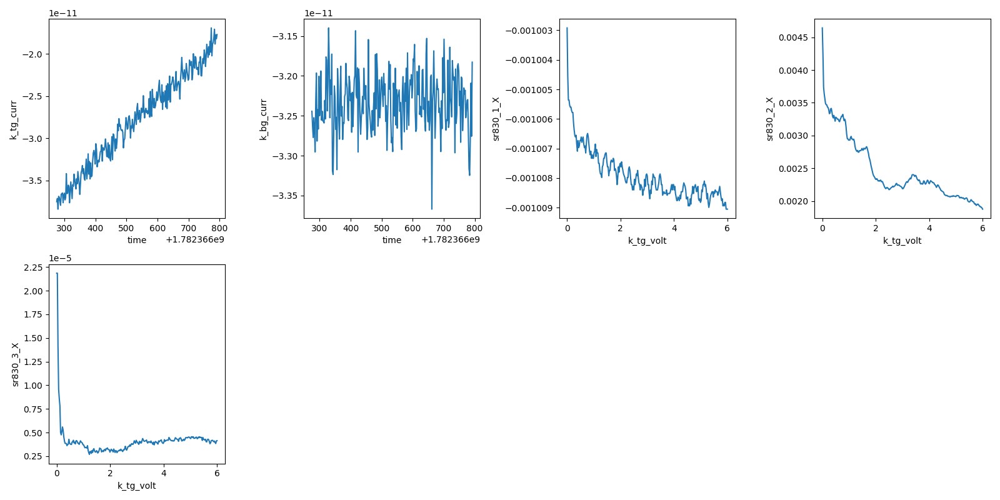

2026-06-24 22:53:13,502 [INFO] Completed in 0h 8m 38s
2026-06-24 22:53:13,503 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-4-zf1\data\0\data.tsv.gz
2026-06-24 22:53:14,020 [INFO] Ramping k_tg_volt: 6.0 -> 0
2026-06-24 22:53:22,081 [INFO] Ramping k_tg_volt: 0.0 -> 0
2026-06-24 22:53:22,601 [INFO] Ramping k_bg_volt: 0.0 -> 0
2026-06-24 22:53:22,609 [INFO] Starting sweep with ID 1
2026-06-24 22:53:22,611 [INFO] Minimum duration 0h 4m 11s


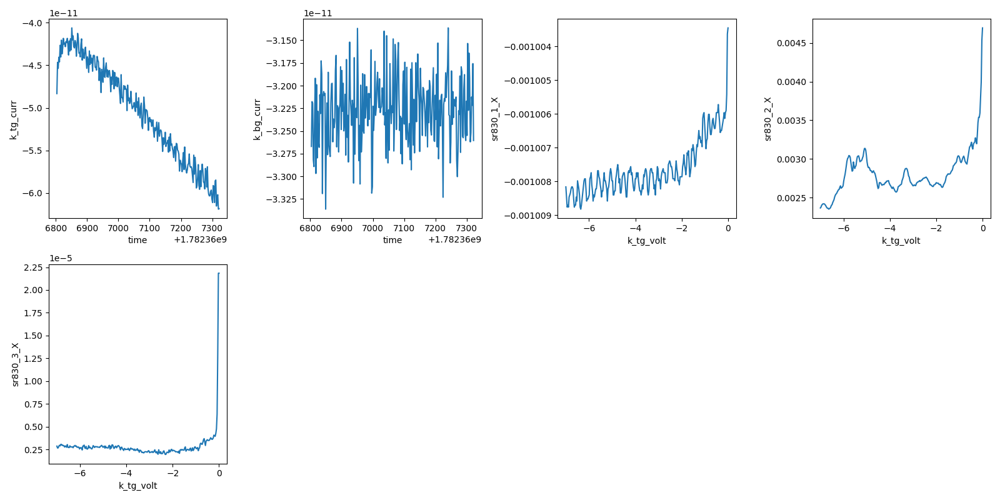

2026-06-24 23:02:03,127 [INFO] Completed in 0h 8m 39s
2026-06-24 23:02:03,127 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-4-zf1\data\1\data.tsv.gz
2026-06-24 23:02:03,638 [INFO] Ramping k_tg_volt: -7.0 -> 0
2026-06-24 23:02:13,097 [INFO] Ramping k_tg_volt: 0.0 -> 0
2026-06-24 23:02:13,617 [INFO] Ramping k_bg_volt: 0.0 -> 0
2026-06-24 23:02:13,627 [INFO] Starting sweep with ID 2
2026-06-24 23:02:13,628 [INFO] Minimum duration 0h 4m 11s


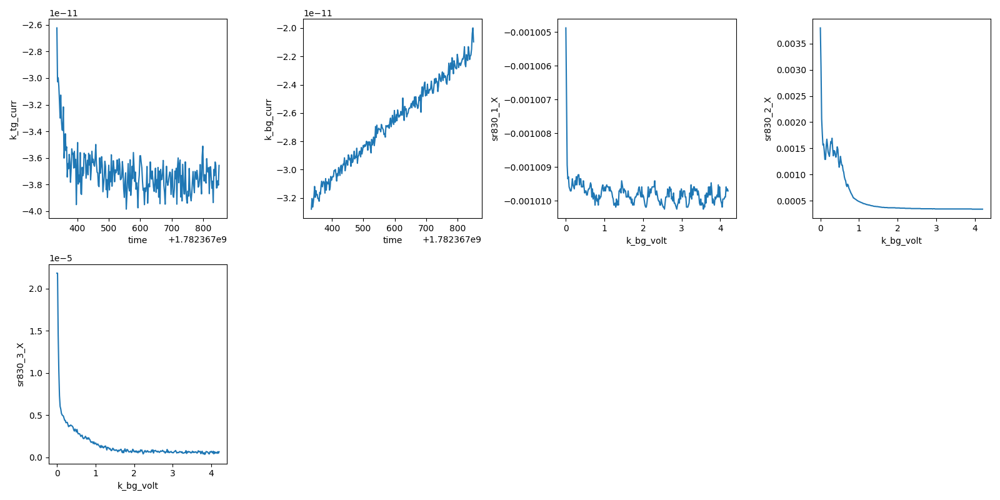

2026-06-24 23:10:52,014 [INFO] Completed in 0h 8m 37s
2026-06-24 23:10:52,014 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-4-zf1\data\2\data.tsv.gz
2026-06-24 23:10:52,533 [INFO] Ramping k_bg_volt: 4.2 -> 0
2026-06-24 23:10:58,397 [INFO] Ramping k_tg_volt: 0.0 -> 0
2026-06-24 23:10:58,909 [INFO] Ramping k_bg_volt: 0.0 -> 0
2026-06-24 23:10:58,917 [INFO] Starting sweep with ID 3
2026-06-24 23:10:58,918 [INFO] Minimum duration 0h 4m 11s


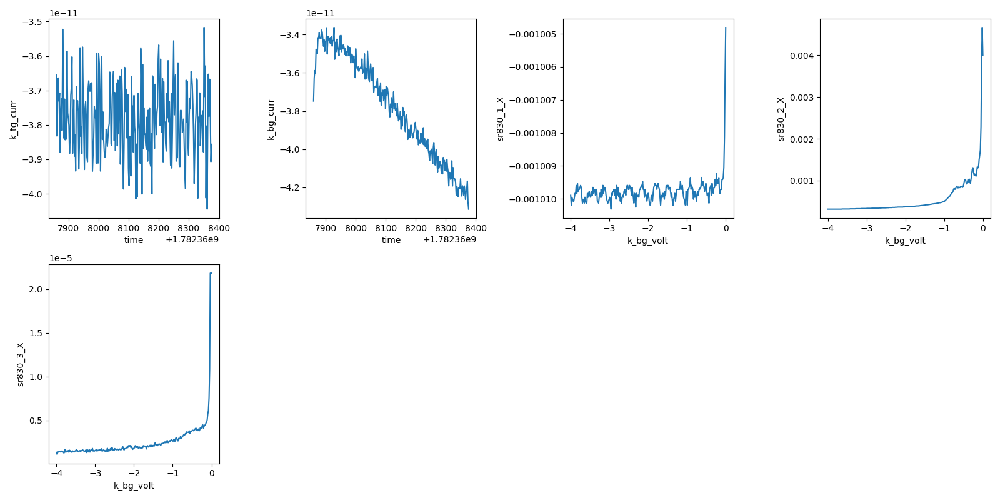

2026-06-24 23:19:37,454 [INFO] Completed in 0h 8m 38s
2026-06-24 23:19:37,455 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-4-zf1\data\3\data.tsv.gz
2026-06-24 23:19:37,971 [INFO] Ramping k_bg_volt: -4.0 -> 0


In [12]:
# === Gate C / liveness: gate-current-sanity-check ===
# Sweep each active gate 0 -> each card limit (other gate parked at 0), watching
# gate current at pA resolution. Safe = pA riding the capacitive charging slope
# to the limit. Gross turn-up off that slope = leak -> Kernel Interrupt (the
# finally parks the gate); stop and report, do NOT run Cell B.

# --- silent-precondition reads (expected vs actual; stop on mismatch) ---
T_now = temperature()
B_now = magnet.field()
print(f"probe MC T : {T_now*1e3:6.1f} mK   (expect base, < ~50 mK)")
print(f"magnet B   : {B_now*1e3:8.4f} mT  (expect ~0; pristine)")
assert T_now < 0.060, f"T too high: {T_now*1e3:.1f} mK"
assert abs(B_now) < 0.005, f"field not at nominal zero: {B_now*1e3:.3f} mT"

# AC sense drive ~1 nA via the 100 MOhm bias R (device card: 0.1 V -> 1 nA)
sr830_1.amplitude(0.1)

# one leg per gate per polarity: (gate, endpoint = committed card limit)
legs = [
    (k_tg, TG_MAX), (k_tg, TG_MIN),
    (k_bg, BG_MAX), (k_bg, BG_MIN),
]
n_pts   = 251
delay   = 1
lockins = [sr830_1, sr830_2, sr830_3]   # current monitor, 2T (5-4), 4T Rxx (30-31)

# pA-floor readback on the gate-current channels; Cell B resets to 1.
k_tg.nplci(10)
k_bg.nplci(10)

for gate, v_endpoint in legs:
    s = sweep.AsyncStation(meas_config)
    s.add_comment('gate-current-sanity-check')
    s.add_comment(f'gate: {gate.name}')
    s.add_comment(f'leg: 0 -> {v_endpoint:+g} V (committed card limit)')

    # park both gates at 0 (the swept one starts from 0)
    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)

    xp = gate.volt
    s.fp(k_tg.volt).fp(k_tg.curr)
    s.fp(k_bg.volt).fp(k_bg.curr)
    s.fp(temperature)
    for lia in lockins:
        s.fp(lia.X).fp(lia.P)

    # session live-plot block (exactly these, in order)
    s.plot('time', k_tg.curr)  # TG leakage
    s.plot('time', k_bg.curr)  # BG leakage
    s.plot(xp, sr830_1.X)      # current monitor (~1 nA flat)
    s.plot(xp, sr830_2.X)      # 2T (5-4)
    s.plot(xp, sr830_3.X)      # 4T Rxx (30-31)

    try:
        s.sweep(gate.volt, np.linspace(0, v_endpoint, n_pts), delay=delay)
    finally:
        s.ramp(gate.volt, 0)


In [13]:
# === Reset gate-current nplci (run ONLY if every leg looked safe) ===
# Validators were committed in the SAFETIES slot — nothing to re-commit here.
k_tg.nplci(1)
k_bg.nplci(1)
print("k_tg.volt validator:", k_tg.volt.vals)
print("k_bg.volt validator:", k_bg.volt.vals)


k_tg.volt validator: <Numbers -7.0<=v<=6.0>
k_bg.volt validator: <Numbers -4.0<=v<=4.2>


## HERA — Pristine-field survey gatemap (investigation Step 1)

Gate C passed (runs 0–3, ana cells 10–12): device alive, wiring good, no leak inside the committed validators. This is the first map of the cooldown and the substrate for the (n, D) calibration the device card flags as an unconfirmed prior, so it is **axis-aligned in raw (V_tg, V_bg)** — no (n, D) conversion error — per gatemap.md, double-duty for cnp-and-dline-calibration. **Pristine field preserved:** the cell does NOT touch the magnet (no ramp), so the map is taken before any remanence is injected (Step-1 field-history discipline); magnet stays at nominal zero.

Parameters: **TG slow** linspace(-6.9, 5.9, 101), **BG fast** linspace(-3.95, 4.15, 101) — brackets the full validator box with a small margin; slow_delay 3, fast_delay 1 (canonical). The CNP line runs diagonally across this box (expected slope dV_tg/dV_bg ~ -1.18 from the prior cap ratio), so it is well sampled for the slope fit. Autorange OFF (canonical — avoids the |phase|<160 no-op quirk mid-row); I set the two voltage lock-ins to 50 mV, sized for Rxx up to ~500 kOhm across the deep CNP (V_xx = I_ac*R*G = 1e-9*R*100). That is coarse on the low-R (candidate-SC) end by design — the survey's job is to locate the CNP + broad low-R region and pin the cap ratio; the tight zoom resizes sensitivity to the candidate. Coverage note: the validator corners/edges (the coverage gate before any not-SC call) come later via edge sweeps; this is the reconnoitre.

Preconditions asserted at the top (T < 60 mK, |B| < 5 mT); nplci reset to 1 for fast readback. **Pricing is not yet calibrated this session** — megasweep rate unknown, so ~1.5–4 h is the bracket. I will hard-checkpoint the first ~3 TG rows the moment they land: measure the true row rate and re-price, confirm leakage stays < 1 nA (surface anything > 100 pA), no channel clipping/flatlining, and Rxx actually varying across the row — abort + re-plan there if any fails.

**Handshake — I am in E0.** First run **Cell B (26)** to close out Gate C (reset nplci), then this map. If you would rather I drive this and the checkpoints myself, say **"go for autonomy"** and I'll record the grant and execute it under E1.


probe MC T :   34.2 mK  (expect base)
magnet B   :  -0.0113 mT (expect ~0; pristine, NOT ramped)
2026-06-24 23:27:08,935 [INFO] Ramping k_tg_volt: 0.0 -> -6.9


2026-06-24 23:27:17,801 [INFO] Ramping k_bg_volt: 0.0 -> -3.95


Sleeping:   0%|          | 0.0/10.0s []

2026-06-24 23:27:32,843 [INFO] Starting megasweep with ID 4


2026-06-24 23:27:32,845 [INFO] Minimum duration 2h 55m 4s


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\parameters\command.py:213: StaleThermometryWarning: T_fridge: freshest logfile (Fridge_MixingCh_low.txt) is 301s old (>300s) — dead worker / wrong probe? T may be stale
  return self.exec_function(*args)


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\parameters\command.py:213: StaleThermometryWarning: T_fridge: freshest logfile (Fridge_MixingCh_low.txt) is 300s old (>300s) — dead worker / wrong probe? T may be stale
  return self.exec_function(*args)


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\parameters\command.py:213: StaleThermometryWarning: T_fridge: freshest logfile (Fridge_MixingCh_low.txt) is 305s old (>300s) — dead worker / wrong probe? T may be stale
  return self.exec_function(*args)


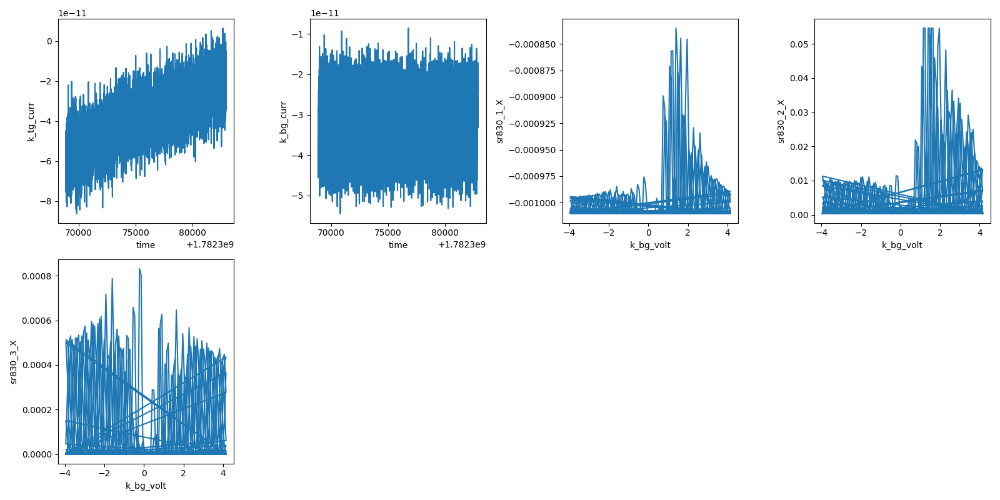

2026-06-25 03:21:58,834 [INFO] Completed in 3h 54m 25s


2026-06-25 03:21:58,835 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-4-zf1\data\4\data.tsv.gz


2026-06-25 03:21:58,897 [INFO] Ramping k_tg_volt: 5.9 -> 0


2026-06-25 03:22:06,447 [INFO] Ramping k_bg_volt: 4.15 -> 0


In [14]:
# === Pristine-field survey gatemap (Step 1) — axis-aligned (V_tg, V_bg) ===
# Cap ratios untrusted -> sweep RAW gate voltages (no (n,D) calibration error).
# Double-duty: substrate for the CNP-slope / cap-ratio calibration.
# PRISTINE FIELD: does NOT touch the magnet — map taken before energising.

# reset gate-current nplci to standard (== Cell B); fast readback for the map
k_tg.nplci(1); k_bg.nplci(1)

# --- silent-precondition reads (expected vs actual; stop on mismatch) ---
T_now = temperature(); B_now = magnet.field()
print(f"probe MC T : {T_now*1e3:6.1f} mK  (expect base)")
print(f"magnet B   : {B_now*1e3:8.4f} mT (expect ~0; pristine, NOT ramped)")
assert T_now < 0.060, f"T too high: {T_now*1e3:.1f} mK"
assert abs(B_now) < 0.005, f"field not at nominal zero: {B_now*1e3:.3f} mT"

# AC sense drive ~1 nA (device card: 0.1 V over 100 MOhm)
sr830_1.amplitude(0.1)
# autorange OFF (canonical); fixed sensitivity for R up to ~500 kOhm at the CNP
sr830_2.sensitivity(0.05)
sr830_3.sensitivity(0.05)

tg = np.linspace(-6.9,  5.9, 101)   # slow
bg = np.linspace(-3.95, 4.15, 101)  # fast

s = sweep.AsyncStation(meas_config)
s.add_comment('gatemap')
s.add_comment('survey: pristine field (B~0, not energised), base T')
s.add_comment(f'V_tg slow [{tg[0]:+g},{tg[-1]:+g}] x{len(tg)}; V_bg fast [{bg[0]:+g},{bg[-1]:+g}] x{len(bg)}')
s.add_comment('double-duty: substrate for cnp-and-dline-calibration')

s.ramp(k_tg.volt, tg[0])
s.ramp(k_bg.volt, bg[0])
interruptable_sleep(10)

xp = k_bg.volt   # fast axis
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(temperature).fp(fridge_temperature)
for lia in (sr830_1, sr830_2, sr830_3):
    s.fp(lia.X).fp(lia.P)

# session live-plot block (exactly these, in order)
s.plot('time', k_tg.curr)  # TG leakage
s.plot('time', k_bg.curr)  # BG leakage
s.plot(xp, sr830_1.X)      # current monitor (~1 nA flat)
s.plot(xp, sr830_2.X)      # 2T (5-4)
s.plot(xp, sr830_3.X)      # 4T Rxx (30-31)

try:
    s.megasweep(k_tg.volt, tg, k_bg.volt, bg, slow_delay=3, fast_delay=1)
finally:
    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)


## HERA — Constant-D n-linecuts: locate the proximity-SC arc (investigation Step 1)

Caps now data-pinned (run 4: c_tg/c_bg=0.844, 99.5% vs prior), so these cuts run in calibrated (n, D). Priors (s41586-022-05446-x): holes toward the WSe2 → D<0; arc at |D| ≳ 0.5 V/nm, n ≈ -4 to -6e11, width ~5e10. Three cuts at **D = -0.45, -0.55, -0.65 V/nm** bracket the |D| prior and test how the arc tracks with D; each scans **n from +1 to -8e11** (0.05e11 step = ~10 pts across the expected arc), wider than the nominal band so a slightly-off prior still catches it. Lines inverted (n,D)→(V_tg,V_bg) with the run-4 calibration, roundtrip-verified, sanitized to validators (D=-0.65 clips to n∈[-8,-2.6], keeping the full target band).

Sensitivity sized for **low Rxx** (the SC dip): 4T (30-31) at 1 mV (10 kΩ ceiling, resolves tens of Ω), 2T at 5 mV — the high-R gapped CNP near n=0 clips **by design**, it is not the target. AC sense stays 1 nA. Preconditions asserted (T<60 mK, |B|<5 mT, gates parked at 0 from run 4). ~15-20 min for all three (≈470 pts total). Executing under E1; I will checkpoint the first cut's first rows (leakage, signal) and read all three from disk at completion — looking for a localized Rxx dip toward 0 on the 4T channel within the target band.


T=34.1 mK  B=0.0024 mT  (gates expected parked at 0)
2026-06-25 03:30:44,710 [INFO] Ramping k_tg_volt: 0.0 -> -3.443060779381253


2026-06-25 03:30:49,160 [INFO] Ramping k_bg_volt: 0.0 -> 3.082151881880294


Sleeping:   0%|          | 0.0/10.0s []

2026-06-25 03:31:03,114 [INFO] Starting multisweep with ID 5


2026-06-25 03:31:03,114 [INFO] Minimum duration 0h 3m 37s


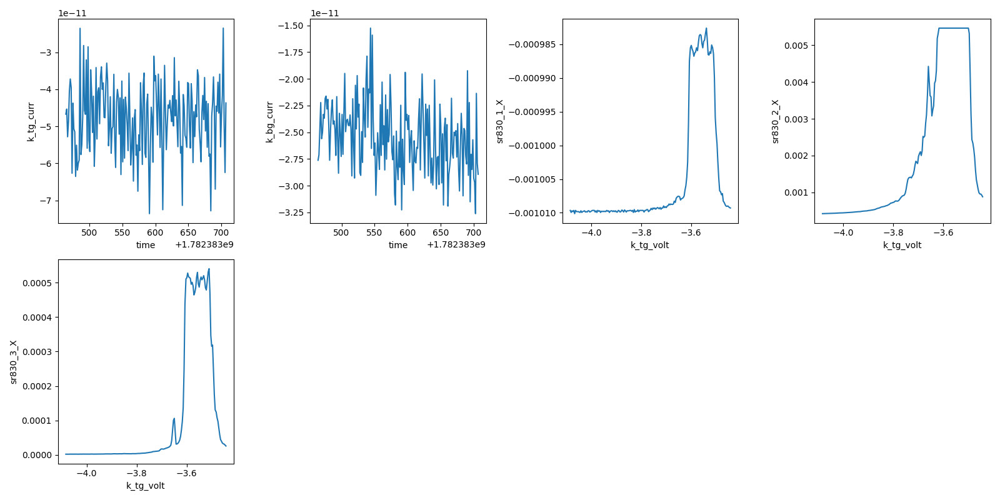

2026-06-25 03:35:07,662 [INFO] Completed in 0h 4m 4s


2026-06-25 03:35:07,662 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-4-zf1\data\5\data.tsv.gz


2026-06-25 03:35:07,727 [INFO] Ramping k_tg_volt: -4.0835 -> 0


2026-06-25 03:35:12,989 [INFO] Ramping k_bg_volt: 2.5395 -> 0


2026-06-25 03:35:16,238 [INFO] Ramping k_tg_volt: 0.0 -> -4.229727446047919


2026-06-25 03:35:21,827 [INFO] Ramping k_bg_volt: 0.0 -> 3.7488185485469607


Sleeping:   0%|          | 0.0/10.0s []

2026-06-25 03:35:36,544 [INFO] Starting multisweep with ID 6


2026-06-25 03:35:36,545 [INFO] Minimum duration 0h 3m 37s


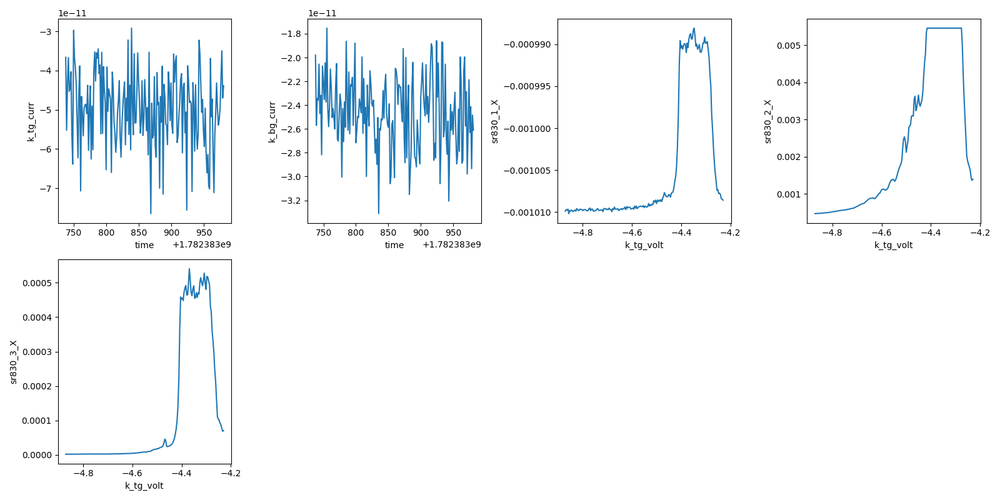

2026-06-25 03:39:41,349 [INFO] Completed in 0h 4m 4s


2026-06-25 03:39:41,350 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-4-zf1\data\6\data.tsv.gz


2026-06-25 03:39:41,414 [INFO] Ramping k_tg_volt: -4.8705 -> 0


2026-06-25 03:39:47,734 [INFO] Ramping k_bg_volt: 3.206 -> 0


2026-06-25 03:39:51,823 [INFO] Ramping k_tg_volt: 0.0 -> -5.2726211275659


2026-06-25 03:39:58,610 [INFO] Ramping k_bg_volt: 0.0 -> 4.198343677204038


Sleeping:   0%|          | 0.0/10.0s []

2026-06-25 03:40:13,887 [INFO] Starting multisweep with ID 7


2026-06-25 03:40:13,887 [INFO] Minimum duration 0h 2m 10s


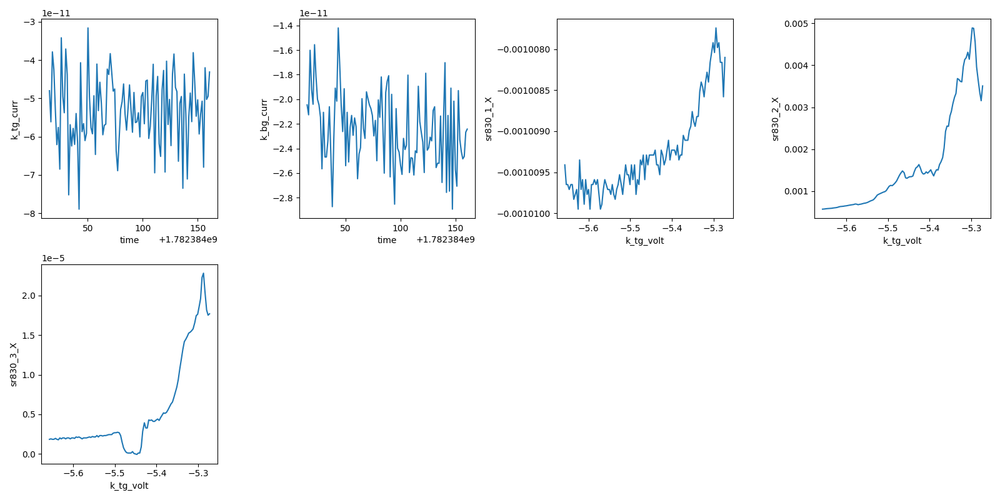

2026-06-25 03:42:41,450 [INFO] Completed in 0h 2m 27s


2026-06-25 03:42:41,451 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-4-zf1\data\7\data.tsv.gz


2026-06-25 03:42:41,513 [INFO] Ramping k_tg_volt: -5.657 -> 0


2026-06-25 03:42:48,793 [INFO] Ramping k_bg_volt: 3.8725 -> 0


In [15]:
# === Constant-D n-linecuts — locate the proximity-SC arc (investigation Step 1) ===
import scipy.constants as cst

# --- silent-precondition reads ---
T_now=temperature(); B_now=magnet.field()
print(f"T={T_now*1e3:.1f} mK  B={B_now*1e3:.4f} mT  (gates expected parked at 0)")
assert T_now<0.060, f"T high {T_now*1e3:.1f} mK"
assert abs(B_now)<0.005, f"B off-zero {B_now*1e3:.3f} mT"

# run-4 calibration: ratio data-pinned (~prior), n_offset from CNP -> n=0
N_OFF = -0.362e11*1e4   # m^-2
cal_r4 = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2, n_offset=N_OFF)
c_tg, c_bg = cal_r4.c_tg, cal_r4.c_bg
e, eps0 = cst.e, cst.epsilon_0
def nD_to_V(n_cm2, D_Vnm):
    n=np.asarray(n_cm2)*1e4; D=np.asarray(D_Vnm)*1e9
    A=(n-cal_r4.n_offset)*e; B=(D-cal_r4.D_offset)*2*eps0
    return (A+B)/(2*c_tg), (A-B)/(2*c_bg)

# low-R sensitivity for the dip hunt (CNP clips by design); AC stays 1 nA
sr830_1.amplitude(0.1)
sr830_2.sensitivity(0.005)   # 2T: 50 kΩ ceiling
sr830_3.sensitivity(0.001)   # 4T: 10 kΩ ceiling -> resolves tens of Ω
k_tg.nplci(1); k_bg.nplci(1)

n_scan = np.arange(1.0, -8.01, -0.05)*1e11
for D0 in (-0.45, -0.55, -0.65):
    vtg, vbg = nD_to_V(n_scan, D0)
    vtg, vbg = sanitize_tg_bg(vtg, vbg, tg_lims, bg_lims)
    s = sweep.AsyncStation(meas_config)
    s.add_comment('cnp-and-dline-calibration')
    s.add_comment('SC-arc linecut (investigation Step 1): constant-D n-cut')
    s.add_comment(f'D={D0:+.2f} V/nm; n in [+1,-8]e11 (0.05 step), {len(vtg)} pts after sanitize')
    s.ramp(k_tg.volt, vtg[0]); s.ramp(k_bg.volt, vbg[0]); interruptable_sleep(10)
    xp = k_tg.volt
    s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr); s.fp(temperature)
    for lia in (sr830_1, sr830_2, sr830_3): s.fp(lia.X).fp(lia.P)
    s.plot('time', k_tg.curr)  # TG leakage
    s.plot('time', k_bg.curr)  # BG leakage
    s.plot(xp, sr830_1.X)      # current monitor
    s.plot(xp, sr830_2.X)      # 2T (5-4)
    s.plot(xp, sr830_3.X)      # 4T Rxx (30-31)
    try:
        s.multisweep([k_tg.volt, k_bg.volt], [vtg, vbg], delay=1.2)
    finally:
        s.ramp(k_tg.volt, 0); s.ramp(k_bg.volt, 0)


## HERA — Tight (n,D) dome zoom around the SC candidate (investigation Step 1 → 2 bridge)

Resolve the candidate dome located in runs 5–7 (Rxx→0 at D=−0.65, n≈−5×10¹¹). Rasterized rectangle in calibrated (n,D): **n ∈ [−3.5, −6.5]×10¹¹ (fast, 0.05 step), D ∈ [−0.55, −0.66] V/nm (slow, 0.01 step)**, boustrophedon, inverted to (V_tg,V_bg) with the run-4 calibration and sanitized to validators. Captures the sharp dip onset (absent at −0.55, strong at −0.65) and the n-extent of the dome (~0.5×10¹¹ wide). **Coverage note (instrument-limited):** at the dome the BG sits at +4.05 V, so |D| beyond ~−0.66 is unreachable this round (BG +4.2 cap) — the high-|D| flank of the dome is validator-limited, not mapped; flagged, not a choice.

Sensitivity low-R (4T 1 mV, 2T 5 mV), AC 1 nA. Preconditions asserted (T<60 mK, |B|<5 mT, gates parked at 0). ~16 min (~730 pts, multisweep delay 1.2). Executing under E1; first-rows leakage/signal checkpoint then disk read at completion. Goal: a closed low-Rxx dome (2D, not a line) — distinguishes a real SC dome from a Hall/artifact zero-crossing locus — and the optimum (n,D) for the bias-spectroscopy Ic test.


T=34.1 mK  B=0.0139 mT (gates expected at 0)
2026-06-25 03:48:09,576 [INFO] Ramping k_tg_volt: 0.0 -> -4.550011214612063


2026-06-25 03:48:15,438 [INFO] Ramping k_bg_volt: 0.0 -> 3.4773916260349744


Sleeping:   0%|          | 0.0/10.0s []

2026-06-25 03:48:29,847 [INFO] Starting multisweep with ID 8


2026-06-25 03:48:29,848 [INFO] Minimum duration 0h 14m 33s


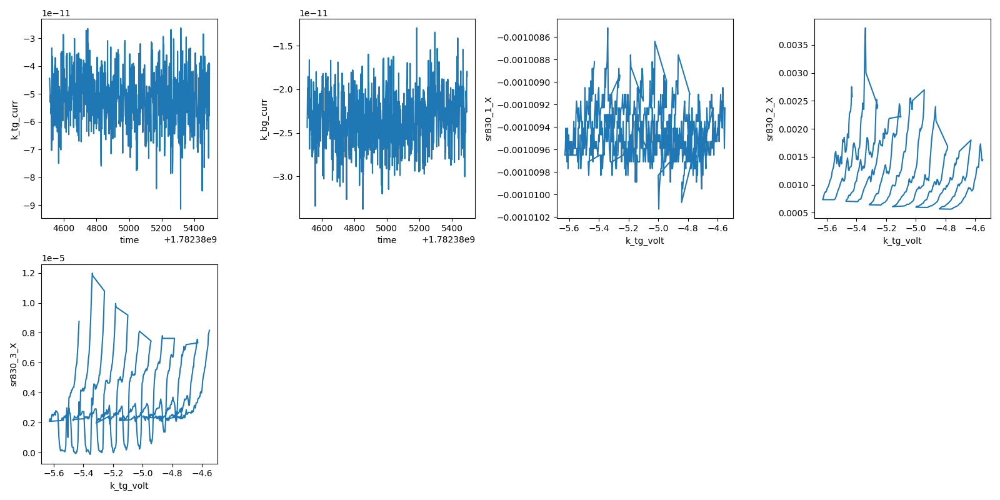

2026-06-25 04:04:53,916 [INFO] Completed in 0h 16m 23s


2026-06-25 04:04:53,917 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-4-zf1\data\8\data.tsv.gz


2026-06-25 04:04:53,978 [INFO] Ramping k_tg_volt: -5.4295 -> 0


2026-06-25 04:05:00,968 [INFO] Ramping k_bg_volt: 4.1985 -> 0


In [16]:
# === Tight (n,D) dome zoom around the SC candidate (nD-map) ===
import scipy.constants as cst
T_now=temperature(); B_now=magnet.field()
print(f"T={T_now*1e3:.1f} mK  B={B_now*1e3:.4f} mT (gates expected at 0)")
assert T_now<0.060 and abs(B_now)<0.005, "precondition fail"

N_OFF=-0.362e11*1e4
cal_r4=GateCalibration.from_thicknesses(t_tg,t_bg,t_bgSiO2,n_offset=N_OFF)
c_tg,c_bg=cal_r4.c_tg,cal_r4.c_bg; e,eps0=cst.e,cst.epsilon_0
def nD_to_V(n_cm2,D_Vnm):
    n=np.asarray(n_cm2)*1e4; D=np.asarray(D_Vnm)*1e9
    A=(n-cal_r4.n_offset)*e; B=(D-cal_r4.D_offset)*2*eps0
    return (A+B)/(2*c_tg),(A-B)/(2*c_bg)

sr830_1.amplitude(0.1)
sr830_2.sensitivity(0.005); sr830_3.sensitivity(0.001)
k_tg.nplci(1); k_bg.nplci(1)

D_slow=np.round(np.arange(-0.55,-0.6601,-0.01),3)   # 12 rows
n_fast=np.arange(-3.5,-6.51,-0.05)                  # 61
vtg_l=[]; vbg_l=[]
for i,D0 in enumerate(D_slow):
    nn = n_fast if i%2==0 else n_fast[::-1]
    vt,vb = nD_to_V(nn*1e11, D0)
    vt,vb = sanitize_tg_bg(vt,vb,tg_lims,bg_lims)
    vtg_l.append(vt); vbg_l.append(vb)
vtg=np.concatenate(vtg_l); vbg=np.concatenate(vbg_l)

s=sweep.AsyncStation(meas_config)
s.add_comment('nD-map')
s.add_comment('SC dome zoom (investigation Step 1): rasterized (n,D) rectangle')
s.add_comment(f'n[-3.5,-6.5]e11 fast x D[-0.55,-0.66] slow; {len(vtg)} pts (boustrophedon, sanitized)')
s.ramp(k_tg.volt, vtg[0]); s.ramp(k_bg.volt, vbg[0]); interruptable_sleep(10)
xp=k_tg.volt
s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr); s.fp(temperature)
for lia in (sr830_1,sr830_2,sr830_3): s.fp(lia.X).fp(lia.P)
s.plot('time', k_tg.curr)
s.plot('time', k_bg.curr)
s.plot(xp, sr830_1.X)
s.plot(xp, sr830_2.X)
s.plot(xp, sr830_3.X)
try:
    s.multisweep([k_tg.volt,k_bg.volt],[vtg,vbg],delay=1.2)
finally:
    s.ramp(k_tg.volt,0); s.ramp(k_bg.volt,0)


## HERA — Bias spectroscopy at the dome optimum: the Ic / supercurrent test (investigation Step 2)

Decisive SC discriminator on the run-8 dome. Operating point = dome optimum **n=−5.0×10¹¹, D=−0.64** (V_tg=−5.36, V_bg=+3.99, inside validators; V_bg 0.2 V under the +4.2 cap). dV/dI vs I_dc: dc205_1 through the 100 MΩ bias R, **round-trip −150→+150→−150 nA** (full reachable range, Vdc ±15 V) — wide bracket to reach the normal state past any switching peak at both ends and to check bias-direction hysteresis (heating/vortex). **AC excitation reduced to 0.5 nA** (amplitude 0.05) per the drive discipline (well below a tens-of-nA Ic, avoids smearing/suppressing a fragile state); 4T (30-31) at 1 mV sensitivity reads dV/dI.

Expect, IF superconducting: dV/dI ≈ 0 for |I_dc| < Ic, rising to the normal-state value (~tens of Ω, the dome surround) at ±Ic with a switching peak. Confounds (consistent-with, not proof): a dV/dI peak alone also arises from non-equilibrium criticality / QH breakdown — so this is hallmark #2 of the constellation, read together with the field-kill and T-dependence to come. Preconditions asserted (T<60 mK, |B|<5 mT, gate setpoints verified after ramp). dc205→0 in the finally; gates left at the dome for the field/T work to follow. ~8 min (302 pts, delay 1.5). Executing under E1; first-rows check then disk read.


T=34.3 mK  B=0.0174 mT
dome opt: n=-5.00e+11 D=-0.64 -> V_tg=-5.365 V_bg=+3.987
2026-06-25 04:09:49,389 [INFO] Ramping k_tg_volt: 0.0 -> -5.36477247080011


2026-06-25 04:09:56,286 [INFO] Ramping k_bg_volt: 0.0 -> 3.986915985197646


Sleeping:   0%|          | 0.0/15.0s []

gates set: V_tg=-5.365 V_bg=+3.987
2026-06-25 04:10:16,560 [INFO] Ramping dc205_1_voltage: 0.0 -> -15.0


Sleeping:   0%|          | 0.0/5.0s []

2026-06-25 04:10:26,152 [INFO] Starting sweep with ID 9


2026-06-25 04:10:26,153 [INFO] Minimum duration 0h 7m 33s


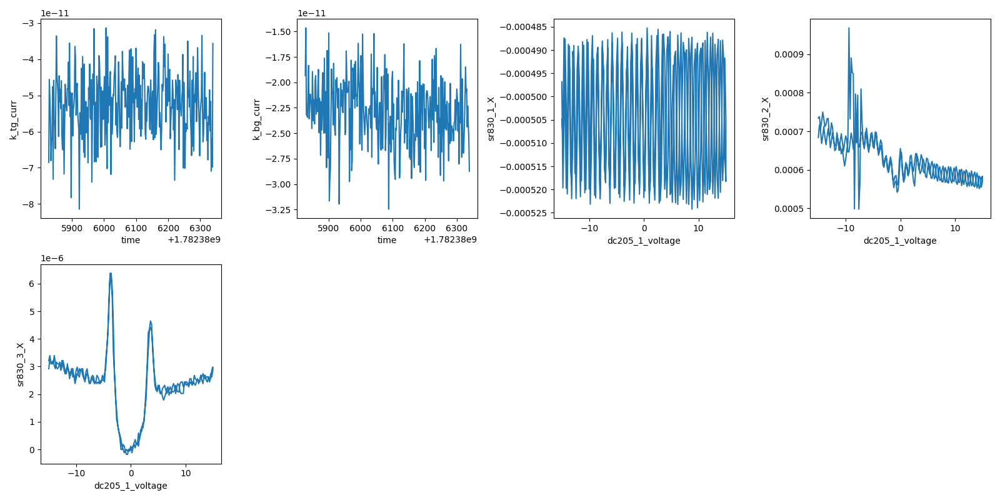

2026-06-25 04:18:59,826 [INFO] Completed in 0h 8m 33s


2026-06-25 04:18:59,827 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-4-zf1\data\9\data.tsv.gz


2026-06-25 04:18:59,833 [INFO] Ramping dc205_1_voltage: -15.0 -> 0


In [17]:
# === Bias spectroscopy (dV/dI vs I_dc) at the dome optimum — Ic test ===
import scipy.constants as cst
T_now=temperature(); B_now=magnet.field()
print(f"T={T_now*1e3:.1f} mK  B={B_now*1e3:.4f} mT")
assert T_now<0.060 and abs(B_now)<0.005, "precondition fail"

# dome optimum (n,D) -> (V_tg,V_bg) via run-4 calibration
N_OFF=-0.362e11*1e4
cal_r4=GateCalibration.from_thicknesses(t_tg,t_bg,t_bgSiO2,n_offset=N_OFF)
c_tg,c_bg=cal_r4.c_tg,cal_r4.c_bg; e,eps0=cst.e,cst.epsilon_0
n0,D0 = -5.0e11, -0.64
A=(n0*1e4-cal_r4.n_offset)*e; B=(D0*1e9-cal_r4.D_offset)*2*eps0
VTG=(A+B)/(2*c_tg); VBG=(A-B)/(2*c_bg)
print(f"dome opt: n={n0:.2e} D={D0} -> V_tg={VTG:+.3f} V_bg={VBG:+.3f}")
assert TG_MIN<VTG<TG_MAX and BG_MIN<VBG<BG_MAX, "dome point outside validators!"

# AC sense reduced to 0.5 nA (drive discipline); 4T reads dV/dI
sr830_1.amplitude(0.05)
sr830_2.sensitivity(0.005); sr830_3.sensitivity(0.001)
k_tg.nplci(1); k_bg.nplci(1)

# set operating point, settle
s0=sweep.AsyncStation(meas_config)  # (ramps below use a station's ramp)
s=sweep.AsyncStation(meas_config)
s.ramp(k_tg.volt, VTG); s.ramp(k_bg.volt, VBG); interruptable_sleep(15)
print(f"gates set: V_tg={k_tg.volt():+.3f} V_bg={k_bg.volt():+.3f}")
assert abs(k_tg.volt()-VTG)<0.02 and abs(k_bg.volt()-VBG)<0.02, "gate setpoint mismatch"

# DC bias round-trip: -15 -> +15 -> -15 V  (= -/+150 nA through 100 MOhm)
Vdc = np.hstack((np.linspace(-15,15,151), np.linspace(15,-15,151)))
s.add_comment('bias-spectroscopy')
s.add_comment(f'dV/dI vs I_dc at dome optimum n={n0:.2e} D={D0} (V_tg={VTG:+.3f},V_bg={VBG:+.3f})')
s.add_comment('round-trip -150..+150..-150 nA (Vdc +/-15V, Rbias 100MOhm); AC 0.5 nA')
s.ramp(dc205_1.volt, Vdc[0]); interruptable_sleep(5)
xp=dc205_1.volt
s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr); s.fp(temperature)
for lia in (sr830_1,sr830_2,sr830_3): s.fp(lia.X).fp(lia.P)
s.plot('time', k_tg.curr)  # TG leakage
s.plot('time', k_bg.curr)  # BG leakage
s.plot(xp, sr830_1.X)      # current monitor
s.plot(xp, sr830_2.X)      # 2T (5-4)
s.plot(xp, sr830_3.X)      # 4T dV/dI (30-31)
try:
    s.sweep(dc205_1.volt, Vdc, delay=1.5)
finally:
    s.ramp(dc205_1.volt, 0)   # device card: dc205 -> 0 when done; gates LEFT at dome


## HERA — Field-kill +side: B_c⊥ at the dome (investigation Step 3), one-sided toward 0

First magnet energization this session. Field response of the SC at the dome (n=−5.0×10¹¹, D=−0.64, gates already there from run 9), zero DC bias (supercurrent state), AC 1 nA sense. **Rig field discipline (brief overrides the recipe's cross-zero idiom):** ramp to +50 mT (position), settle, then sweep **+50→0 mT monotonically toward 0** — never increasing |B| through 0 while measuring; ramp heating is worst near 0, so ending at 0 with per-step settling protects the SC point. 101 pts (0.5 mT step), delay 1.5 s.

This is the **+side only** — I read it first (B_c⊥ scale, effective-zero location given the ~2 mT trapped flux, ramp-heating behavior) before doing the −side and any range extension. Expect: Rxx ≈ normal (~57 Ω) at +50 mT falling to ≈0 as B→ the SC's effective zero — a small B⊥ that removes the low-Rxx state (field-kill) is hallmark #3 (consistent-with SC). Preconditions asserted; prints ramp_rate and T after the positioning ramp (calibrates the settle for later field runs). |B| ≤ 50 mT, well inside the 100 mT cap. Field returns to 0 at the end (leaves ≤~10 mT remanence — noted for downstream). ~6 min.


In [18]:
# === Field-kill +side: B_c-perp at the dome (field-sweep-1d, one-sided toward 0) ===
import scipy.constants as cst
T0=temperature(); B0=magnet.field()
rr=magnet.ramp_rate()
print(f"T={T0*1e3:.1f} mK  B={B0*1e3:.4f} mT  ramp_rate={rr*1e3:.3f} mT/s")
assert T0<0.060, "T high"
assert abs(B0)<0.005, "field not near 0 at start"

N_OFF=-0.362e11*1e4
cal_r4=GateCalibration.from_thicknesses(t_tg,t_bg,t_bgSiO2,n_offset=N_OFF)
c_tg,c_bg=cal_r4.c_tg,cal_r4.c_bg; e,eps0=cst.e,cst.epsilon_0
n0,D0=-5.0e11,-0.64
A=(n0*1e4-cal_r4.n_offset)*e; Bd=(D0*1e9)*2*eps0
VTG=(A+Bd)/(2*c_tg); VBG=(A-Bd)/(2*c_bg)
print(f"dome V_tg={VTG:+.3f} V_bg={VBG:+.3f}; live V_tg={k_tg.volt():+.3f} V_bg={k_bg.volt():+.3f}")

sr830_1.amplitude(0.1)    # 1 nA sense
sr830_2.sensitivity(0.005); sr830_3.sensitivity(0.001)
k_tg.nplci(1); k_bg.nplci(1)

s=sweep.AsyncStation(meas_config)
s.ramp(k_tg.volt, VTG); s.ramp(k_bg.volt, VBG); s.ramp(dc205_1.volt, 0)
s.add_comment('field-sweep-1d')
s.add_comment(f'B_c-perp field-kill +side at dome n={n0:.2e} D={D0}; sweep +50->0 mT (one-sided toward 0)')
xp=mag.field
s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr); s.fp(temperature); s.fp(mag.field)
for lia in (sr830_1,sr830_2,sr830_3): s.fp(lia.X).fp(lia.P)
s.plot('time', k_tg.curr); s.plot('time', k_bg.curr)
s.plot(xp, sr830_1.X); s.plot(xp, sr830_2.X); s.plot(xp, sr830_3.X)

B_MAX=0.05
s.ramp(mag.field, +B_MAX)               # position (blocks until holding)
interruptable_sleep(90)                  # thermal settle after ramp
print(f"after +ramp+settle: T={temperature()*1e3:.1f} mK  B={magnet.field()*1e3:.3f} mT")
try:
    s.sweep(mag.field, np.linspace(+B_MAX, 0.0, 101), delay=1.5)   # measure, toward 0
finally:
    mag.field(0.0)                        # leave at nominal 0; gates stay at dome
print(f"end: B={magnet.field()*1e3:.3f} mT  T={temperature()*1e3:.1f} mK")


T=34.1 mK  B=0.0106 mT  ramp_rate=1.000 mT/s
dome V_tg=-5.365 V_bg=+3.987; live V_tg=-5.365 V_bg=+3.987


2026-06-25 04:24:17,691 [INFO] Ramping k_tg_volt: -5.365 -> -5.36477247080011


2026-06-25 04:24:17,754 [INFO] Ramping k_bg_volt: 3.987 -> 3.986915985197646


2026-06-25 04:24:17,761 [INFO] Ramping dc205_1_voltage: 0.0 -> 0


NameError: name 'mag' is not defined

## HERA — field-kill +side (re-run, corrected: mag→magnet)\nPrevious attempt (cell 36) hit NameError at xp=mag.field **before any field move** (B stayed 0.011 mT, gates at dome, dc205=0). Same measurement, corrected to the rig's instrument name 'magnet'. ramp_rate measured 1.0 mT/s.

T=34.1 mK  B=0.0066 mT  ramp_rate=1.000 mT/s
dome V_tg=-5.365 V_bg=+3.987; live V_tg=-5.365 V_bg=+3.987


2026-06-25 04:25:18,475 [INFO] Ramping k_tg_volt: -5.365 -> -5.36477247080011


2026-06-25 04:25:18,539 [INFO] Ramping k_bg_volt: 3.987 -> 3.986915985197646


2026-06-25 04:25:18,551 [INFO] Ramping dc205_1_voltage: 0.0 -> 0


2026-06-25 04:25:18,596 [INFO] Ramping magnet_field: 1.4793e-05 -> 0.05


Sleeping:   0%|          | 0.0/90.0s []

after +ramp+settle: T=35.1 mK  B=50.007 mT
2026-06-25 04:27:48,999 [INFO] Starting sweep with ID 10


2026-06-25 04:27:48,999 [INFO] Minimum duration 0h 2m 31s


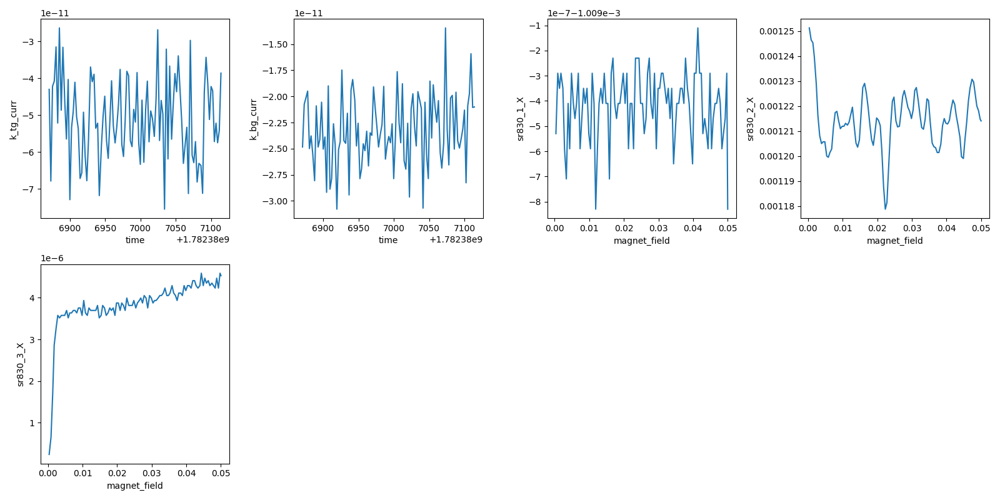

2026-06-25 04:31:54,620 [INFO] Completed in 0h 4m 5s


2026-06-25 04:31:54,621 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-4-zf1\data\10\data.tsv.gz


end: B=0.263 mT  T=34.9 mK


In [19]:
# === Field-kill +side: B_c-perp at the dome (field-sweep-1d, one-sided toward 0) ===
import scipy.constants as cst
T0=temperature(); B0=magnet.field()
rr=magnet.ramp_rate()
print(f"T={T0*1e3:.1f} mK  B={B0*1e3:.4f} mT  ramp_rate={rr*1e3:.3f} mT/s")
assert T0<0.060, "T high"
assert abs(B0)<0.005, "field not near 0 at start"

N_OFF=-0.362e11*1e4
cal_r4=GateCalibration.from_thicknesses(t_tg,t_bg,t_bgSiO2,n_offset=N_OFF)
c_tg,c_bg=cal_r4.c_tg,cal_r4.c_bg; e,eps0=cst.e,cst.epsilon_0
n0,D0=-5.0e11,-0.64
A=(n0*1e4-cal_r4.n_offset)*e; Bd=(D0*1e9)*2*eps0
VTG=(A+Bd)/(2*c_tg); VBG=(A-Bd)/(2*c_bg)
print(f"dome V_tg={VTG:+.3f} V_bg={VBG:+.3f}; live V_tg={k_tg.volt():+.3f} V_bg={k_bg.volt():+.3f}")

sr830_1.amplitude(0.1)    # 1 nA sense
sr830_2.sensitivity(0.005); sr830_3.sensitivity(0.001)
k_tg.nplci(1); k_bg.nplci(1)

s=sweep.AsyncStation(meas_config)
s.ramp(k_tg.volt, VTG); s.ramp(k_bg.volt, VBG); s.ramp(dc205_1.volt, 0)
s.add_comment('field-sweep-1d')
s.add_comment(f'B_c-perp field-kill +side at dome n={n0:.2e} D={D0}; sweep +50->0 mT (one-sided toward 0)')
xp=magnet.field
s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr); s.fp(temperature); s.fp(magnet.field)
for lia in (sr830_1,sr830_2,sr830_3): s.fp(lia.X).fp(lia.P)
s.plot('time', k_tg.curr); s.plot('time', k_bg.curr)
s.plot(xp, sr830_1.X); s.plot(xp, sr830_2.X); s.plot(xp, sr830_3.X)

B_MAX=0.05
s.ramp(magnet.field, +B_MAX)               # position (blocks until holding)
interruptable_sleep(90)                  # thermal settle after ramp
print(f"after +ramp+settle: T={temperature()*1e3:.1f} mK  B={magnet.field()*1e3:.3f} mT")
try:
    s.sweep(magnet.field, np.linspace(+B_MAX, 0.0, 101), delay=1.5)   # measure, toward 0
finally:
    magnet.field(0.0)                        # leave at nominal 0; gates stay at dome
print(f"end: B={magnet.field()*1e3:.3f} mT  T={temperature()*1e3:.1f} mK")


## HERA — field-kill fine symmetric (±15→0 mT): B_c⊥ + effective zero\nTwo one-sided sweeps toward 0 (+15→0 then −15→0) at 0.15 mT step, dome point, zero DC bias, AC 1 nA. Pins B_c⊥ (run 10 showed ~2-3 mT) and locates the SC effective-zero field (the Rxx minimum, offset from nominal 0 by trapped flux/remanence); the kill should mirror about it. Ramp heating negligible (run 10: T held 35 mK). ~9 min.

T=34.5 mK  B=-0.0161 mT  ramp_rate=1.00 mT/s
2026-06-25 04:34:05,032 [INFO] Ramping k_tg_volt: -5.365 -> -5.36477247080011


2026-06-25 04:34:05,094 [INFO] Ramping k_bg_volt: 3.987 -> 3.986915985197646


2026-06-25 04:34:05,109 [INFO] Ramping dc205_1_voltage: 0.0 -> 0


2026-06-25 04:34:05,139 [INFO] Ramping magnet_field: -3.974e-06 -> 0.015


Sleeping:   0%|          | 0.0/45.0s []

+ramp done: T=34.7mK B=15.026mT
2026-06-25 04:35:14,186 [INFO] Starting sweep with ID 11


2026-06-25 04:35:14,187 [INFO] Minimum duration 0h 2m 1s


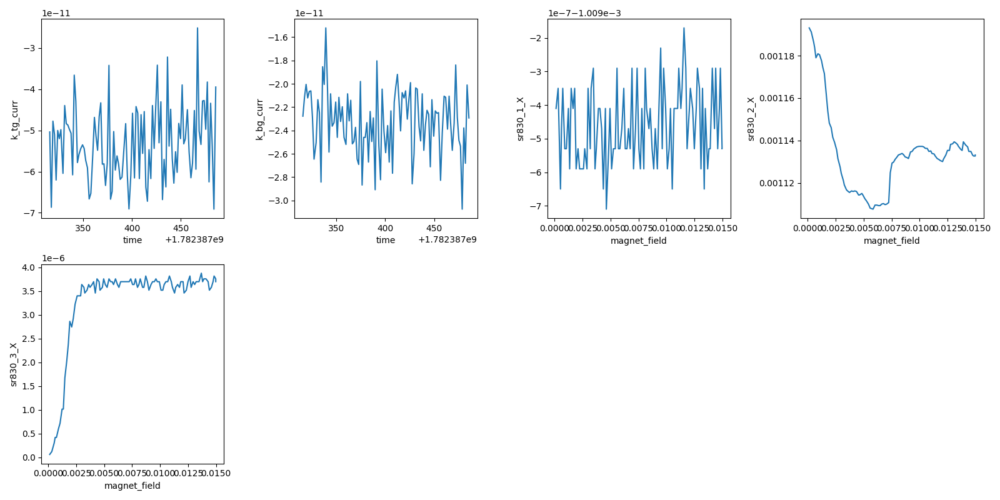

2026-06-25 04:38:06,362 [INFO] Completed in 0h 2m 51s


2026-06-25 04:38:06,363 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-4-zf1\data\11\data.tsv.gz


2026-06-25 04:38:06,481 [INFO] Ramping magnet_field: 0.000128056 -> -0.015


Sleeping:   0%|          | 0.0/45.0s []

-ramp done: T=34.9mK B=-15.025mT
2026-06-25 04:39:16,727 [INFO] Starting sweep with ID 12


2026-06-25 04:39:16,728 [INFO] Minimum duration 0h 2m 1s


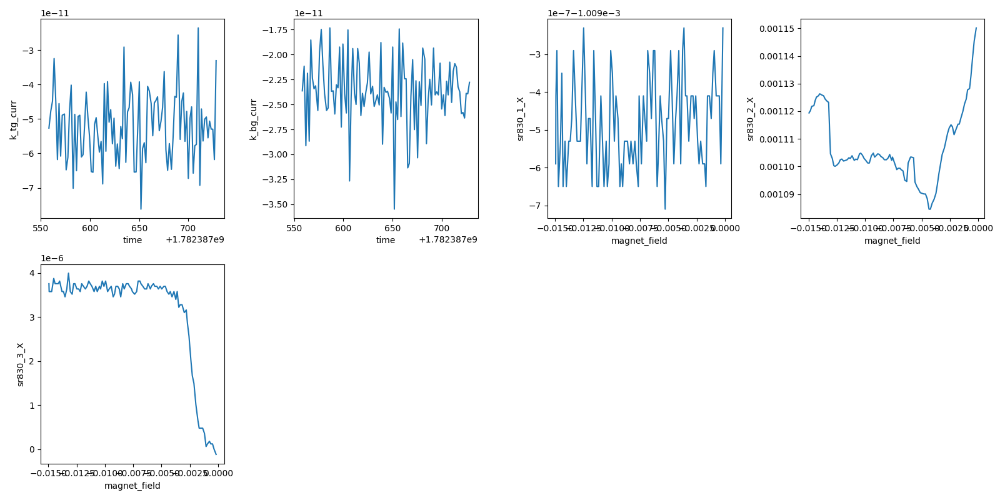

2026-06-25 04:42:08,948 [INFO] Completed in 0h 2m 51s


2026-06-25 04:42:08,949 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-4-zf1\data\12\data.tsv.gz


end: B=-0.089mT T=34.7mK

In [20]:
# === Field-kill fine symmetric (+/-15->0 mT) — B_c-perp + effective zero ===
import scipy.constants as cst
T0=temperature(); B0=magnet.field()
print(f"T={T0*1e3:.1f} mK  B={B0*1e3:.4f} mT  ramp_rate={magnet.ramp_rate()*1e3:.2f} mT/s")
assert T0<0.060, "T high"

N_OFF=-0.362e11*1e4
cal_r4=GateCalibration.from_thicknesses(t_tg,t_bg,t_bgSiO2,n_offset=N_OFF)
c_tg,c_bg=cal_r4.c_tg,cal_r4.c_bg; e,eps0=cst.e,cst.epsilon_0
n0,D0=-5.0e11,-0.64
A=(n0*1e4-cal_r4.n_offset)*e; Bd=(D0*1e9)*2*eps0
VTG=(A+Bd)/(2*c_tg); VBG=(A-Bd)/(2*c_bg)

sr830_1.amplitude(0.1)
sr830_2.sensitivity(0.005); sr830_3.sensitivity(0.001)
k_tg.nplci(1); k_bg.nplci(1)

s=sweep.AsyncStation(meas_config)
s.ramp(k_tg.volt, VTG); s.ramp(k_bg.volt, VBG); s.ramp(dc205_1.volt, 0)
s.add_comment('field-sweep-1d')
s.add_comment(f'B_c-perp fine symmetric +/-15->0 mT at dome n={n0:.2e} D={D0}; one-sided toward 0 each side')
xp=magnet.field
s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr); s.fp(temperature); s.fp(magnet.field)
for lia in (sr830_1,sr830_2,sr830_3): s.fp(lia.X).fp(lia.P)
s.plot('time', k_tg.curr); s.plot('time', k_bg.curr)
s.plot(xp, sr830_1.X); s.plot(xp, sr830_2.X); s.plot(xp, sr830_3.X)

BM=0.015
# +side fine: position +15mT, settle, sweep +15->0
s.ramp(magnet.field, +BM); interruptable_sleep(45)
print(f"+ramp done: T={temperature()*1e3:.1f}mK B={magnet.field()*1e3:.3f}mT")
s.sweep(magnet.field, np.linspace(+BM, 0.0, 101), delay=1.2)
# -side fine: position -15mT, settle, sweep -15->0
s.ramp(magnet.field, -BM); interruptable_sleep(45)
print(f"-ramp done: T={temperature()*1e3:.1f}mK B={magnet.field()*1e3:.3f}mT")
s.sweep(magnet.field, np.linspace(-BM, 0.0, 101), delay=1.2)
magnet.field(0.0)
print(f"end: B={magnet.field()*1e3:.3f}mT T={temperature()*1e3:.1f}mK")


## HERA — T-dependence: Ic(T) ladder at the dome (investigation Step 4, heat up LAST)

Final constellation hallmark. Flavor-B T-ladder at the dome (n=−5.0×10¹¹, D=−0.64, B=0=effective zero). Open-loop heater stepped **up in ≤1 V increments** (rig heater discipline) through V=[0,1,2,3,4,5,6,6.5] → roughly 30→480 mK (device-card map; T read back from data, not the setpoint). At each step: confirm heater drawing current, thermalize (8–18 min, scaled to level per rig card), then a **dV/dI vs I_dc bias sweep ±60 nA** (AC 0.5 nA) — Ic(T) from each; Ic→0 brackets Tc. 8 files. Heater ceiling 6.5 V sustained (validator) — **if Ic has not collapsed by 480 mK, Tc is heater-ceiling-limited and I'll say so** (no Tesla field / no higher T this round).

~1.5–2 h. T-dependence is last because the thermal cycle is the expensive, least-reversible step. Heater→0 at the end (no base-recovery wait needed — session-final). Per step I checkpoint T-settling (data T column) and the Ic value; I interrupt if the fridge destabilizes (rig card flags a possible instability trip). Executing under E1; this is a long auto-run, operator notified.


start: T=34.3 mK  B=-0.017 mT
2026-06-25 04:47:18,795 [INFO] Ramping k_tg_volt: -5.365 -> -5.36477247080011


2026-06-25 04:47:18,857 [INFO] Ramping k_bg_volt: 3.987 -> 3.986915985197646


2026-06-25 04:47:18,927 [INFO] Ramping heater_volt: 0.0 -> 0


heater=0V  I_heater=0.000 mA -> thermalize 8 min


Sleeping:   0%|          | 0.0/480.0s []

  after dwell: T=34.2 mK (heater 0V)
2026-06-25 04:55:21,021 [INFO] Ramping dc205_1_voltage: 0.0 -> -6.0


Sleeping:   0%|          | 0.0/3.0s []

2026-06-25 04:55:25,822 [INFO] Starting sweep with ID 13


2026-06-25 04:55:25,822 [INFO] Minimum duration 0h 1m 1s


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\parameters\command.py:213: StaleThermometryWarning: T_fridge: freshest logfile (Fridge_MixingCh_low.txt) is 467s old (>300s) — dead worker / wrong probe? T may be stale
  return self.exec_function(*args)


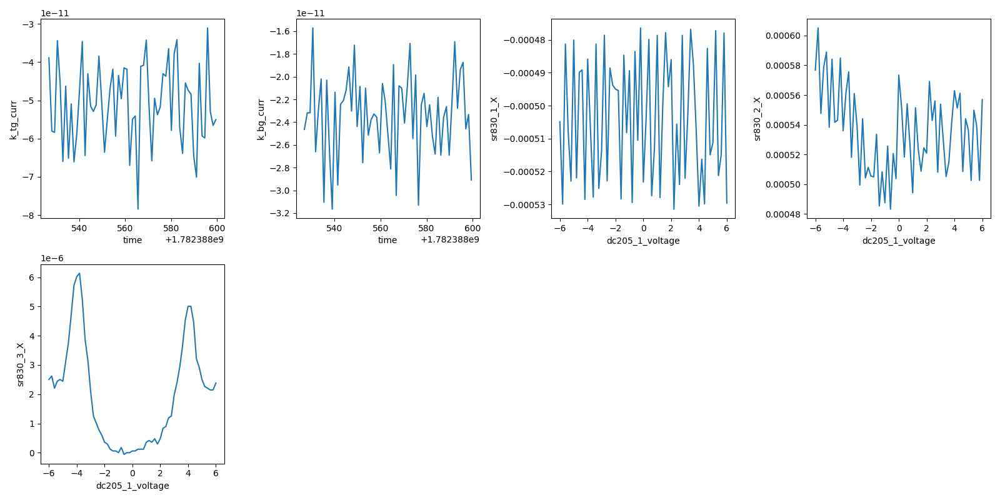

2026-06-25 04:56:40,155 [INFO] Completed in 0h 1m 13s


2026-06-25 04:56:40,156 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-4-zf1\data\13\data.tsv.gz


2026-06-25 04:56:40,166 [INFO] Ramping dc205_1_voltage: 6.0 -> 0


2026-06-25 04:56:41,936 [INFO] Ramping k_tg_volt: -5.365 -> -5.36477247080011


2026-06-25 04:56:41,998 [INFO] Ramping k_bg_volt: 3.987 -> 3.986915985197646


...

Sleeping:   0%|          | 0.0/480.0s []

  after dwell: T=54.1 mK (heater 1V)
2026-06-25 05:04:45,424 [INFO] Ramping dc205_1_voltage: 0.0 -> -6.0


Sleeping:   0%|          | 0.0/3.0s []

2026-06-25 05:04:50,219 [INFO] Starting sweep with ID 14


2026-06-25 05:04:50,220 [INFO] Minimum duration 0h 1m 1s


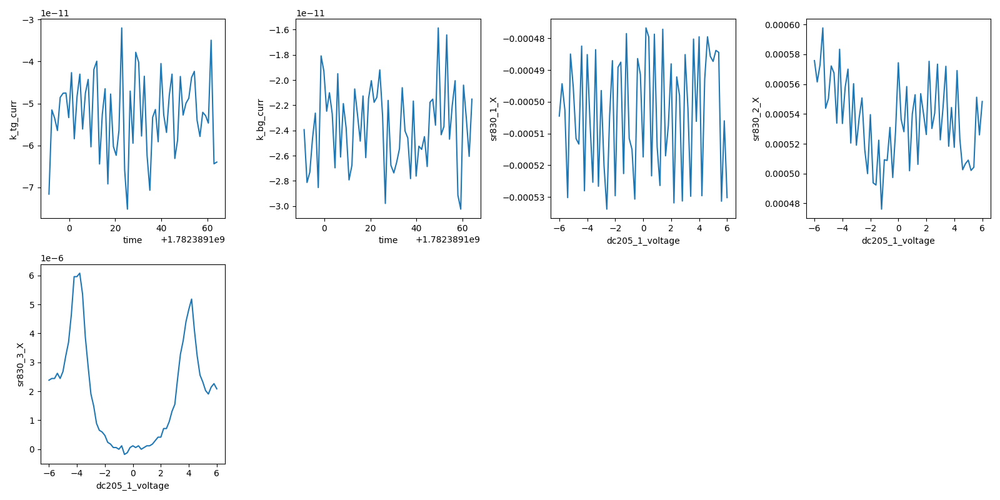

2026-06-25 05:06:04,847 [INFO] Completed in 0h 1m 14s


2026-06-25 05:06:04,848 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-4-zf1\data\14\data.tsv.gz


2026-06-25 05:06:04,859 [INFO] Ramping dc205_1_voltage: 6.0 -> 0


2026-06-25 05:06:06,617 [INFO] Ramping k_tg_volt: -5.365 -> -5.36477247080011


2026-06-25 05:06:06,680 [INFO] Ramping k_bg_volt: 3.987 -> 3.986915985197646


...

Sleeping:   0%|          | 0.0/480.0s []

  after dwell: T=100.7 mK (heater 2V)
2026-06-25 05:14:10,096 [INFO] Ramping dc205_1_voltage: 0.0 -> -6.0


Sleeping:   0%|          | 0.0/3.0s []

2026-06-25 05:14:14,883 [INFO] Starting sweep with ID 15


2026-06-25 05:14:14,883 [INFO] Minimum duration 0h 1m 1s


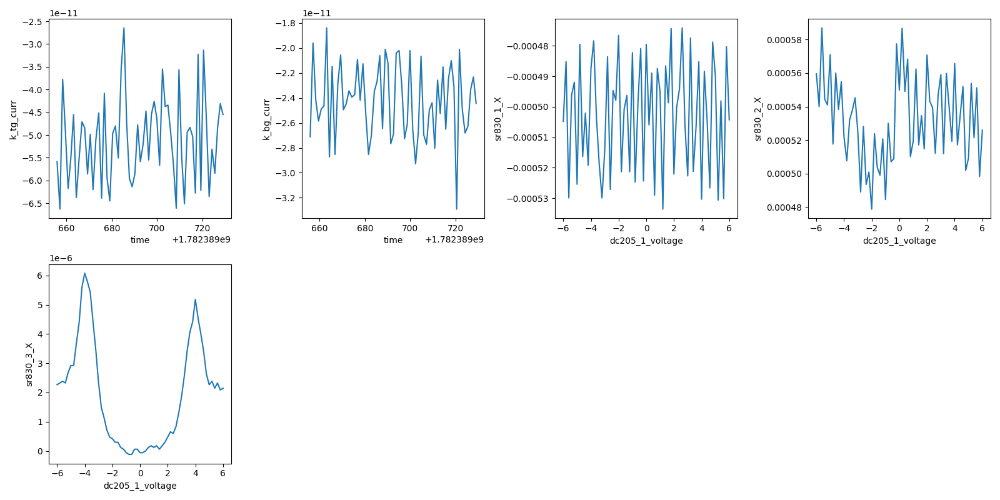

2026-06-25 05:15:29,715 [INFO] Completed in 0h 1m 14s


2026-06-25 05:15:29,716 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-4-zf1\data\15\data.tsv.gz


2026-06-25 05:15:29,724 [INFO] Ramping dc205_1_voltage: 6.0 -> 0


2026-06-25 05:15:31,547 [INFO] Ramping k_tg_volt: -5.365 -> -5.36477247080011


2026-06-25 05:15:31,616 [INFO] Ramping k_bg_volt: 3.987 -> 3.986915985197646


...

Sleeping:   0%|          | 0.0/480.0s []

  after dwell: T=157.6 mK (heater 3V)
2026-06-25 05:23:35,058 [INFO] Ramping dc205_1_voltage: 0.0 -> -6.0


Sleeping:   0%|          | 0.0/3.0s []

2026-06-25 05:23:39,864 [INFO] Starting sweep with ID 16


2026-06-25 05:23:39,865 [INFO] Minimum duration 0h 1m 1s


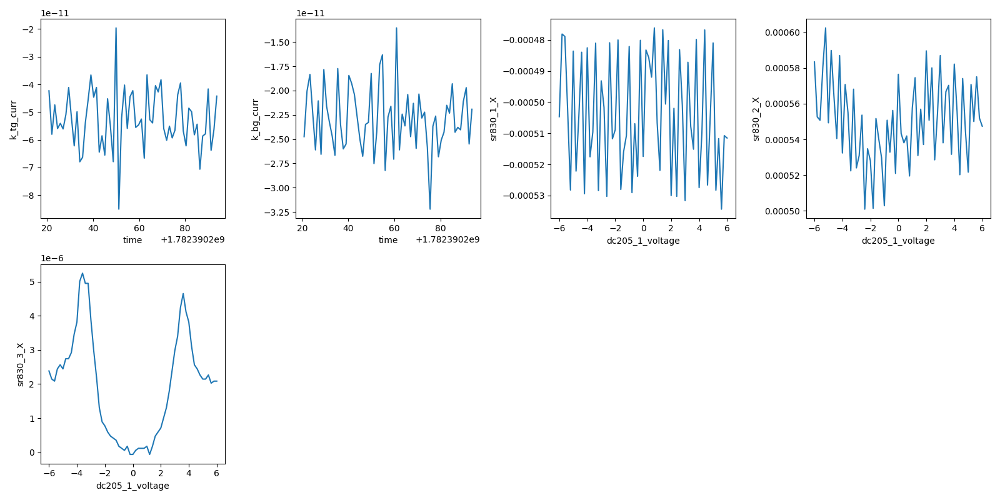

2026-06-25 05:24:54,395 [INFO] Completed in 0h 1m 13s


2026-06-25 05:24:54,396 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-4-zf1\data\16\data.tsv.gz


2026-06-25 05:24:54,412 [INFO] Ramping dc205_1_voltage: 6.0 -> 0


2026-06-25 05:24:56,170 [INFO] Ramping k_tg_volt: -5.365 -> -5.36477247080011


2026-06-25 05:24:56,233 [INFO] Ramping k_bg_volt: 3.987 -> 3.986915985197646


...

Sleeping:   0%|          | 0.0/600.0s []

  after dwell: T=228.4 mK (heater 4V)
2026-06-25 05:34:59,651 [INFO] Ramping dc205_1_voltage: 0.0 -> -6.0


Sleeping:   0%|          | 0.0/3.0s []

2026-06-25 05:35:04,446 [INFO] Starting sweep with ID 17


2026-06-25 05:35:04,447 [INFO] Minimum duration 0h 1m 1s


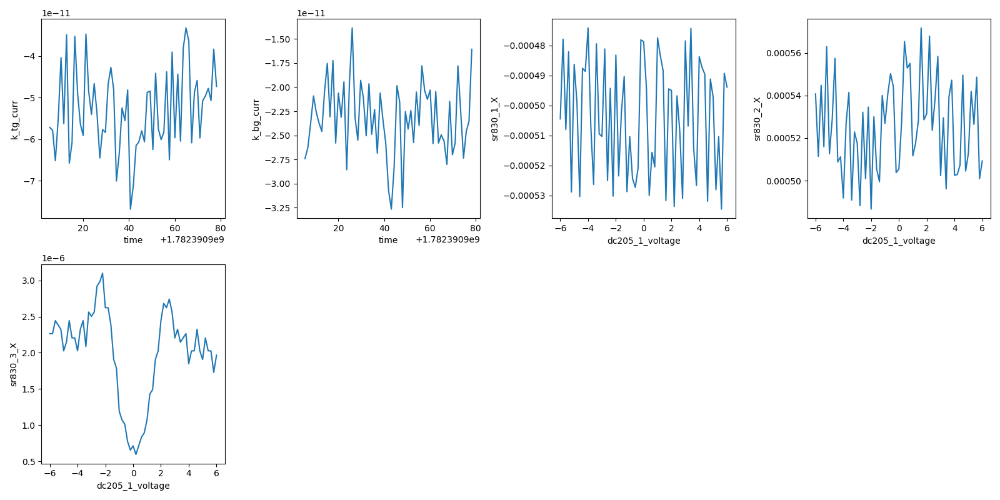

2026-06-25 05:36:18,903 [INFO] Completed in 0h 1m 13s


2026-06-25 05:36:18,904 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-4-zf1\data\17\data.tsv.gz


2026-06-25 05:36:18,907 [INFO] Ramping dc205_1_voltage: 6.0 -> 0


2026-06-25 05:36:20,673 [INFO] Ramping k_tg_volt: -5.365 -> -5.36477247080011


2026-06-25 05:36:20,736 [INFO] Ramping k_bg_volt: 3.987 -> 3.986915985197646


...

Sleeping:   0%|          | 0.0/840.0s []

  after dwell: T=322.1 mK (heater 5V)
2026-06-25 05:50:24,173 [INFO] Ramping dc205_1_voltage: 0.0 -> -6.0


Sleeping:   0%|          | 0.0/3.0s []

2026-06-25 05:50:28,957 [INFO] Starting sweep with ID 18


2026-06-25 05:50:28,958 [INFO] Minimum duration 0h 1m 1s


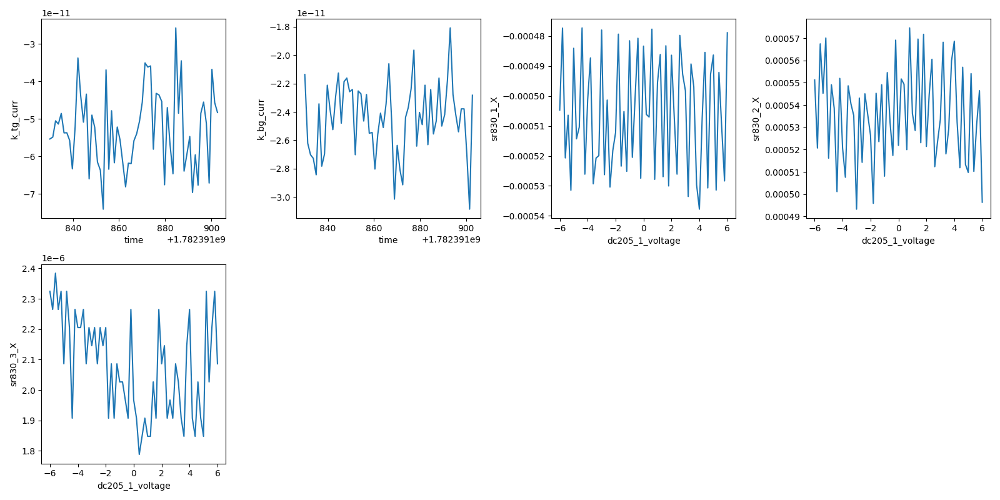

2026-06-25 05:51:43,414 [INFO] Completed in 0h 1m 13s


2026-06-25 05:51:43,415 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-4-zf1\data\18\data.tsv.gz


2026-06-25 05:51:43,429 [INFO] Ramping dc205_1_voltage: 6.0 -> 0


2026-06-25 05:51:45,203 [INFO] Ramping k_tg_volt: -5.365 -> -5.36477247080011


2026-06-25 05:51:45,267 [INFO] Ramping k_bg_volt: 3.987 -> 3.986915985197646


...

Sleeping:   0%|          | 0.0/1080.0s []

  after dwell: T=430.6 mK (heater 6V)
2026-06-25 06:09:48,693 [INFO] Ramping dc205_1_voltage: 0.0 -> -6.0


Sleeping:   0%|          | 0.0/3.0s []

2026-06-25 06:09:53,491 [INFO] Starting sweep with ID 19


2026-06-25 06:09:53,491 [INFO] Minimum duration 0h 1m 1s


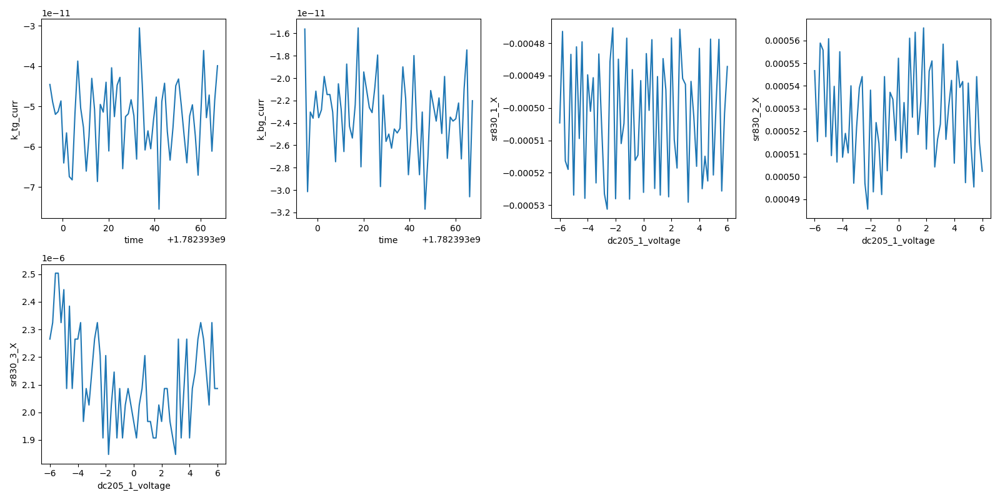

2026-06-25 06:11:08,111 [INFO] Completed in 0h 1m 14s


2026-06-25 06:11:08,112 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-4-zf1\data\19\data.tsv.gz


2026-06-25 06:11:08,126 [INFO] Ramping dc205_1_voltage: 6.0 -> 0


2026-06-25 06:11:09,908 [INFO] Ramping k_tg_volt: -5.365 -> -5.36477247080011


2026-06-25 06:11:09,979 [INFO] Ramping k_bg_volt: 3.987 -> 3.986915985197646


...

Sleeping:   0%|          | 0.0/1080.0s []

  after dwell: T=488.9 mK (heater 6.5V)
2026-06-25 06:29:12,767 [INFO] Ramping dc205_1_voltage: 0.0 -> -6.0


Sleeping:   0%|          | 0.0/3.0s []

2026-06-25 06:29:17,555 [INFO] Starting sweep with ID 20


2026-06-25 06:29:17,556 [INFO] Minimum duration 0h 1m 1s


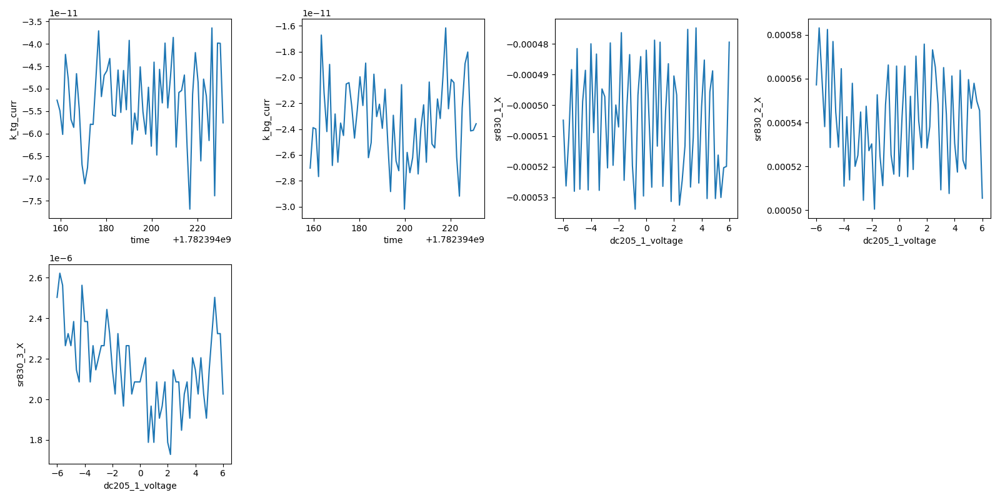

2026-06-25 06:30:32,023 [INFO] Completed in 0h 1m 13s


2026-06-25 06:30:32,024 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-4-zf1\data\20\data.tsv.gz


2026-06-25 06:30:32,041 [INFO] Ramping dc205_1_voltage: 6.0 -> 0


heater off. T now 486.7 mK


In [21]:
# === T-dependence: Ic(T) ladder at the dome (Flavor B, heat up last) ===
import scipy.constants as cst, time
T0=temperature(); B0=magnet.field()
print(f"start: T={T0*1e3:.1f} mK  B={B0*1e3:.3f} mT")
assert T0<0.060, "not at base"
assert abs(B0)<0.005, "field not ~0"

N_OFF=-0.362e11*1e4
cal_r4=GateCalibration.from_thicknesses(t_tg,t_bg,t_bgSiO2,n_offset=N_OFF)
c_tg,c_bg=cal_r4.c_tg,cal_r4.c_bg; e,eps0=cst.e,cst.epsilon_0
n0,D0=-5.0e11,-0.64
A=(n0*1e4-cal_r4.n_offset)*e; Bd=(D0*1e9)*2*eps0
VTG=(A+Bd)/(2*c_tg); VBG=(A-Bd)/(2*c_bg)

sr830_1.amplitude(0.05)   # 0.5 nA drive discipline
sr830_2.sensitivity(0.005); sr830_3.sensitivity(0.001)
k_tg.nplci(1); k_bg.nplci(1)

# dwell schedule (s) by heater level (rig card: ~15min/1V, longer >4V)
def dwell(h):
    if h<=3: return 8*60
    if h<=4: return 10*60
    if h<=5: return 14*60
    return 18*60

Vdc=np.linspace(-6,6,61)   # +/-60 nA
h_steps=[0,1,2,3,4,5,6,6.5]
try:
    for h in h_steps:
        s=sweep.AsyncStation(meas_config)
        s.ramp(k_tg.volt, VTG); s.ramp(k_bg.volt, VBG)
        s.ramp(heater.volt, h)              # <=1V step from previous
        time.sleep(2); i_h=heater.curr()
        print(f"heater={h}V  I_heater={i_h*1e3:.3f} mA -> thermalize {dwell(h)//60} min")
        interruptable_sleep(dwell(h))
        Tnow=temperature()
        print(f"  after dwell: T={Tnow*1e3:.1f} mK (heater {h}V)")
        s.add_comment('temperature-dependence')
        s.add_comment(f'Ic(T) ladder at dome n={n0:.2e} D={D0}; heater={h}V')
        s.add_comment(f'T_readback={Tnow*1e3:.1f}mK; dV/dI vs I_dc +/-60nA, AC 0.5nA')
        xp=dc205_1.volt
        s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr)
        s.fp(temperature).fp(fridge_temperature).fp(heater.volt).fp(heater.curr)
        for lia in (sr830_1,sr830_2,sr830_3): s.fp(lia.X).fp(lia.P)
        s.plot('time', k_tg.curr); s.plot('time', k_bg.curr)
        s.plot(xp, sr830_1.X); s.plot(xp, sr830_2.X); s.plot(xp, sr830_3.X)
        s.ramp(dc205_1.volt, Vdc[0]); interruptable_sleep(3)
        s.sweep(dc205_1.volt, Vdc, delay=1.0)
        s.ramp(dc205_1.volt, 0)
finally:
    heater.volt(0)            # heater off (session-final; no base-recovery wait)
    print(f"heater off. T now {temperature()*1e3:.1f} mK")
